Model A: Pollutant-Based AQI Prediction Using Random Forest

Objective: To predict the Air Quality Index (AQI) using pollutant measurements and date-related features from daily air-quality data collected between 2015 and 2020.

The model will be trained on data from 2015–2019 and evaluated on data from 2020. This chronological split allows us to evaluate performance on a later period rather than randomly mixing past and future observations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/content/city_day.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
print(df.columns.tolist())
print("\nMissing values in each column:")
print(df.isnull().sum())

['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Missing values in each column:
City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64


In [4]:
# Make a copy so the original dataframe remains unchanged
data = df.copy()

# Convert Date to a proper date format
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Remove rows without a valid date or AQI target
data = data.dropna(subset=["Date", "AQI"])

# Remove duplicate city-date observations
data = data.drop_duplicates(subset=["City", "Date"])

# Keep the study period from 2015 to 2020
data = data[
    (data["Date"] >= "2015-01-01") &
    (data["Date"] < "2021-01-01")
].copy()

# Sort chronologically within each city
data = data.sort_values(["City", "Date"]).reset_index(drop=True)

print("Shape after basic cleaning:", data.shape)
print("Date range:", data["Date"].min(), "to", data["Date"].max())
print("Missing AQI values:", data["AQI"].isna().sum())

data.head()

Shape after basic cleaning: (24850, 16)
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00
Missing AQI values: 0


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-29,83.13,NaN,6.93,28.71,33.72,NaN,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor
1,Ahmedabad,2015-01-30,79.84,NaN,13.85,28.68,41.08,NaN,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor
2,Ahmedabad,2015-01-31,94.52,NaN,24.39,32.66,52.61,NaN,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe
3,Ahmedabad,2015-02-01,135.99,NaN,43.48,42.08,84.57,NaN,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe
4,Ahmedabad,2015-02-02,178.33,NaN,54.56,35.31,72.80,NaN,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe


In [5]:
# Pollutant columns that may be present in the dataset
possible_pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

# Keep only columns that actually exist
pollutant_cols = [
    col for col in possible_pollutants if col in data.columns
]

print("Pollutant features selected:")
print(pollutant_cols)

if not pollutant_cols:
    raise ValueError("No expected pollutant columns were found. Check df.columns.")

Pollutant features selected:
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']


In [6]:
data["Month"] = data["Date"].dt.month
data["DayOfWeek"] = data["Date"].dt.dayofweek
data["Year"] = data["Date"].dt.year

print(data[["Date", "Year", "Month", "DayOfWeek"]].head())

        Date  Year  Month  DayOfWeek
0 2015-01-29  2015      1          3
1 2015-01-30  2015      1          4
2 2015-01-31  2015      1          5
3 2015-02-01  2015      2          6
4 2015-02-02  2015      2          0


In [7]:
train_data = data[data["Date"] < "2020-01-01"].copy()
test_data = data[
    (data["Date"] >= "2020-01-01") &
    (data["Date"] < "2021-01-01")
].copy()

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training rows: 20429
Testing rows: 4421

Training period:
2015-01-01 00:00:00 to 2019-12-31 00:00:00

Testing period:
2020-01-01 00:00:00 to 2020-07-01 00:00:00


In [8]:
feature_cols = pollutant_cols + [
    "City", "Month", "DayOfWeek"
]

X_train = train_data[feature_cols]
y_train = train_data["AQI"]

X_test = test_data[feature_cols]
y_test = test_data["AQI"]

numeric_features = pollutant_cols + ["Month", "DayOfWeek"]
categorical_features = ["City"]

print("Number of input features:", len(feature_cols))
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

Number of input features: 15
Training feature shape: (20429, 15)
Testing feature shape: (4421, 15)


In [9]:
# Fill missing numerical feature values using training-set medians
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Convert city names into numerical indicator columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build the complete Random Forest pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("random_forest", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Model pipeline created successfully!")

Model pipeline created successfully!


In [10]:
model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [11]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual_AQI": y_test.values,
    "Predicted_AQI": y_pred
})

results.head(10)

,Actual_AQI,Predicted_AQI
0,216.0,203.98
1,162.0,169.19
2,220.0,243.74
3,254.0,269.14
4,255.0,200.61
5,175.0,199.29
6,285.0,264.86
7,157.0,141.10
8,129.0,136.07
9,129.0,163.79


In [12]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Regression Results")
print("--------------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.3f}")

Random Forest Regression Results
--------------------------------
MAE:  16.11
RMSE: 26.70
R²:   0.898


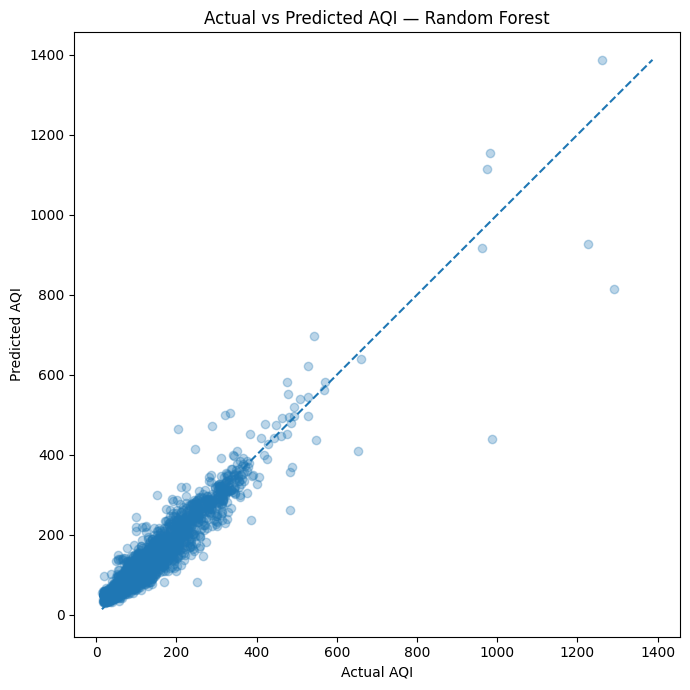

In [13]:
plt.figure(figsize=(7, 7))

plt.scatter(y_test, y_pred, alpha=0.3)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI — Random Forest")
plt.tight_layout()
plt.show()

In [14]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    model.named_steps["random_forest"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
0,numeric__PM2.5,0.478273
6,numeric__CO,0.374346
2,numeric__NO,0.037834
1,numeric__PM10,0.034617
8,numeric__O3,0.013068
4,numeric__NOx,0.011678
7,numeric__SO2,0.009096
3,numeric__NO2,0.008856
10,numeric__Toluene,0.005949
11,numeric__Xylene,0.004829


In [15]:
import os

os.makedirs("/content/outputs", exist_ok=True)

metrics_df = pd.DataFrame([{
    "Model": "Random Forest Regression",
    "Training_Period": "2015-2019",
    "Testing_Period": "2020",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}])

metrics_df.to_csv("/content/outputs/model_a_metrics.csv", index=False)
results.to_csv("/content/outputs/model_a_predictions.csv", index=False)
importance_df.to_csv("/content/outputs/model_a_feature_importance.csv", index=False)

print("Metrics, predictions, and feature importance saved.")

Metrics, predictions, and feature importance saved.


In [16]:
results["Absolute_Error"] = abs(
    results["Actual_AQI"] - results["Predicted_AQI"]
)

results.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,Actual_AQI,Predicted_AQI,Absolute_Error
74,988.0,438.41,549.59
45,1291.0,813.30,477.70
44,1226.0,927.91,298.09
24,204.0,465.44,261.44
34,652.0,409.02,242.98
22,483.0,261.15,221.85
3926,289.0,471.61,182.61
33,322.0,500.26,178.26
52,983.0,1154.86,171.86
16,334.0,505.45,171.45


In [17]:
# Recover the original test-set row information
error_analysis = test_data.loc[
    y_test.index if hasattr(y_test, "index") else test_data.index
].copy()

# Reset indices so the predictions align with the test rows
error_analysis = test_data.reset_index(drop=True).copy()

error_analysis["Actual_AQI"] = y_test.reset_index(drop=True)
error_analysis["Predicted_AQI"] = y_pred
error_analysis["Absolute_Error"] = abs(
    error_analysis["Actual_AQI"] -
    error_analysis["Predicted_AQI"]
)

# Show the 10 observations with the largest errors
error_analysis.sort_values(
    "Absolute_Error",
    ascending=False
)[
    ["City", "Date", "AQI", "Actual_AQI",
     "Predicted_AQI", "Absolute_Error"]
].head(10)

,City,Date,AQI,Actual_AQI,Predicted_AQI,Absolute_Error
74,Ahmedabad,2020-03-19,988.0,988.0,438.41,549.59
45,Ahmedabad,2020-02-19,1291.0,1291.0,813.30,477.70
44,Ahmedabad,2020-02-18,1226.0,1226.0,927.91,298.09
24,Ahmedabad,2020-01-29,204.0,204.0,465.44,261.44
34,Ahmedabad,2020-02-08,652.0,652.0,409.02,242.98
22,Ahmedabad,2020-01-23,483.0,483.0,261.15,221.85
3926,Talcher,2020-01-25,289.0,289.0,471.61,182.61
33,Ahmedabad,2020-02-07,322.0,322.0,500.26,178.26
52,Ahmedabad,2020-02-26,983.0,983.0,1154.86,171.86
16,Ahmedabad,2020-01-17,334.0,334.0,505.45,171.45


In [18]:
error_analysis.groupby("City").agg(
    Number_of_Observations=("Actual_AQI", "count"),
    Mean_Absolute_Error=("Absolute_Error", "mean"),
    Mean_Actual_AQI=("Actual_AQI", "mean")
).sort_values(
    "Mean_Absolute_Error",
    ascending=False
).head(10)

,Number_of_Observations,Mean_Absolute_Error,Mean_Actual_AQI
City,,,
Ahmedabad,176,45.054205,242.068182
Lucknow,183,22.930492,157.125683
Aizawl,111,22.692883,34.765766
Patna,183,21.346940,162.251366
Talcher,156,21.133942,160.692308
Brajrajnagar,121,21.107541,137.107438
Guwahati,183,20.637541,161.508197
Gurugram,183,17.010492,158.655738
Jorapokhar,162,16.898909,145.339506


### Conclusion

A Random Forest regression model was developed to estimate the Air Quality Index (AQI) using pollutant measurements and date-related features. The model was trained on observations from 2015–2019 and evaluated on data from 2020.

The model achieved a Mean Absolute Error (MAE) of 16.11, a Root Mean Squared Error (RMSE) of 26.70, and an R² score of 0.898 on the test dataset. The actual-versus-predicted plot showed that the model captured the general relationship between actual and predicted AQI, although some observations had large prediction errors, particularly at high AQI values.

Further investigation would be useful to understand the errors associated with extreme AQI observations and to assess whether model performance differs across cities.

This model estimates AQI when pollutant measurements are available. Predicting future AQI would require a separate forecasting approach using information available before the prediction time.
